## Analysis: Which natural features of a climbing route determine its grade?

## 1. Library imports

In [1]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx=g++ -fexhaustive-register-search"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re
import unicodedata
import bambi as bmb
import arviz as az
import h5netcdf

## 2. Data imports

In [2]:
df = pd.read_csv("annotation_finale_ponderee.csv")
df

C:\Users\lunag\AppData\Local\Temp\ipykernel_22364\1127046363.py:1: DtypeWarning: Columns (31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("annotation_finale_ponderee.csv")


,document_id,title,title_prefix,quality,activities,climbing_outdoor_type,global_rating,engagement_rating,risk_rating,equipment_rating,...,arête_ponderation,couloir_ponderation,trou_ponderation,réglette_ponderation,cannelure_ponderation,goutte_eau_ponderation,plat_ponderation,bac_ponderation,éperon_ponderation,crochet_ponderation
0,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1944609,Capricho,Aiguille de la Canalona,medium,rock_climbing,multi,D+,NaN,NaN,P2+,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42856,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42857,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42858,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42859,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Data manipulation

In [3]:
ordre_cotations = [
    "1a", "1b", "1b+", "1c+", 
    "2a", "2a+", "2b", "2b+", "2c", "2c+", 
    "3a", "3a+", "3b", "3b+", "3c", "3c+", 
    "4a", "4a+", "4b", "4b+", "4c", "4c+", 
    "5a", "5a+", "5b", "5b+", "5c", "5c+", 
    "6a", "6a+", "6b", "6b+", "6c", "6c+",
    "7a", "7a+", "7b", "7b+", "7c", "7c+", 
    "8a", "8a+", "8b", "8b+", "8c", "8c+",
    "9a+"
]


In [4]:
# Grade order

df["difficulty"] = pd.Categorical(
    df["difficulty"],
    categories=ordre_cotations,
    ordered=True
)

In [5]:
# Frequent elements: kept as numeric counts, capped at 3
elements_frequents = [
    "dalle", "fissure", "dièdre", "traversée", "surplomb",
    "dévers", "cheminée", "vire", "arête", "pilier", "terrasse", "éperon"
]

# Intermediate-frequency elements: binarized as present/absent
elements_intermediaires = [
    "écailles", "trou", "couloir", "cannelure", "réglette",
    "goutte_eau", "crochet", "bac", "plat", "petite_prise"
]

# Very rare elements: excluded from the model
elements_rares = [
    "pince", "mono_doigt", "bi_doigt", "contrefort", "corniche",
    "épaule", "inversee", "fissure-dièdre"
]

# --- Build the analysis dataset (df remains unchanged) ---
df_model = df.copy()

# 1. Frequent elements: numeric counts capped at 3
for e in elements_frequents:
    df_model[f"nb_{e}"] = pd.to_numeric(df_model[f"nb_{e}"]).clip(upper=3)

# 2. Intermediate-frequency elements: binarized as pres_<element>
for e in elements_intermediaires:
    df_model[f"pres_{e}"] = (pd.to_numeric(df_model[f"nb_{e}"]) > 0).astype(int)

# 3. Select final columns: model variables + identifiers
colonnes_modele = (
    [f"nb_{e}"  for e in elements_frequents] +
    [f"pres_{e}" for e in elements_intermediaires]
)
df_model = df_model[colonnes_modele + ["difficulty", "document_id", 'log_nb_terms_description']].copy()

# 4. Remove incomplete rows (if any NaNs remain)
df_model = df_model.dropna(subset=colonnes_modele + ["difficulty"]).reset_index(drop=True)

## 4. Analysis

In [6]:
# ============================================================
# PARAMETERS TO ADJUST
# ============================================================
COL_COTATION = "difficulty"                 # French climbing grade (e.g. 6a, 6a+...)
COL_VOIE = "document_id"
PREDICTEURS = ['nb_dalle',
 'nb_fissure',
 'nb_dièdre',
 'nb_traversée',
 'nb_surplomb',
 'nb_dévers',
 'nb_cheminée',
 'nb_vire',
 'nb_arête',
 'nb_pilier',
 'nb_terrasse',
 'nb_éperon',
 'pres_écailles',
 'pres_trou',
 'pres_couloir',
 'pres_cannelure',
 'pres_réglette',
 'pres_goutte_eau',
 'pres_crochet',
 'pres_bac',
 'pres_plat',
 'pres_petite_prise',
 'log_nb_terms_description']   

# Grade classes: cap the rare extremes; 15 classes here
COTATION_MIN = "4c+"                        # all values <= this threshold are grouped into class 1
COTATION_MAX = "7a+"                        # all values >= this threshold are grouped into the last class

SEPARER_ENTRE_INTRA = False                 # True: separate within-route and between-route effects
N_VOIES_TEST = 300                         # e.g. 300 for a quick test; None = all

DOSSIER = "resultats"
PREFIXE = os.path.join(DOSSIER, "ordinaleB_Total_bambi")

In [7]:
# ============================================================
# TOOLS
# ============================================================
def nettoyer_nom(nom):
    """Column name without accents or special characters (required for Bambi formulas)."""
    s = unicodedata.normalize("NFKD", nom).encode("ascii", "ignore").decode()
    return re.sub(r"\W+", "_", s).strip("_")


ORDRE = [f"{n}{l}{p}" for n in range(1, 10) for l in "abc" for p in ["", "+"]]
RANG = {g: i for i, g in enumerate(ORDRE)}


def cotation_vers_classe(serie):
    """Grade -> increasing integer (1 = easiest), with extremes grouped."""
    rang = serie.astype("string").str.strip().str.lower().map(RANG).astype(float)
    bas, haut = RANG[COTATION_MIN], RANG[COTATION_MAX]
    return rang.clip(lower=bas, upper=haut) - bas + 1

In [8]:
# ============================================================
# 1. DATA PREPARATION
# ============================================================

data = pd.DataFrame({
    "classe_cotation": cotation_vers_classe(df_model[COL_COTATION]),
    COL_VOIE: df_model[COL_VOIE],
})
noms_propres = {p: nettoyer_nom(p) for p in PREDICTEURS}
for p, propre in noms_propres.items():
    data[propre] = pd.to_numeric(df_model[p], errors="coerce")
predicteurs = list(noms_propres.values())

data = data.dropna(subset=["classe_cotation"] + predicteurs).copy()
data["classe_cotation"] = data["classe_cotation"].astype(int)
print(f"{len(data)} rows, {data[COL_VOIE].nunique()} routes, "
      f"{data['classe_cotation'].nunique()} grade classes")

if N_VOIES_TEST:
    voies = data[COL_VOIE].drop_duplicates().sample(N_VOIES_TEST, random_state=0)
    data = data[data[COL_VOIE].isin(voies)].copy()
    print(f"Quick test: {data[COL_VOIE].nunique()} routes, {len(data)} lignes")

if SEPARER_ENTRE_INTRA:
    nouvelles = []
    for p in predicteurs:
        moyenne = data.groupby(COL_VOIE)[p].transform("mean")
        data[p + "_moy_voie"] = moyenne          # between-route effect
        data[p + "_ecart"] = data[p] - moyenne   # within-route effect
        nouvelles += [p + "_ecart", p + "_moy_voie"]
    predicteurs = nouvelles

SEUIL_FUSION = 20 if N_VOIES_TEST else 400
effectifs = data["classe_cotation"].value_counts().sort_index()
mapping = {}
for c in effectifs.index:
    if effectifs[c] < SEUIL_FUSION and (c - 1) in effectifs.index:
        mapping[c] = c - 1      # merge into the lower grade class
    else:
        mapping[c] = c
data["classe_cotation"] = data["classe_cotation"].map(mapping)
print("Grade-class counts after merging:")
print(data["classe_cotation"].value_counts().sort_index())

os.makedirs(DOSSIER, exist_ok=True)
data.to_csv(os.path.join(DOSSIER, "donnees_prepareesB.csv"), index=False)

42861 rows, 9299 routes, 15 grade classes
Quick test: 300 routes, 1295 lignes
Grade-class counts after merging:
classe_cotation
1     162
2      70
4     146
6     194
7      31
8     207
9     139
10    129
11     59
12     70
13     37
14     27
15     24
Name: count, dtype: int64


In [9]:
exclues = {"classe_cotation", COL_VOIE}
predicteurs_modele = [c for c in data.columns if c not in exclues]   # initially


# 1) Data: standardization + winsorization (as in the R script)
df_bayes = data.copy()
for p in predicteurs_modele:
    x = df_bayes[p].astype(float)
    z = (x - x.mean()) / x.std()
    df_bayes[p] = z.clip(-10, 10)          # winsorization at ±10

# 2) Response = ORDERED category (required for the cumulative family)
categories = sorted(df_bayes["classe_cotation"].unique())
df_bayes["classe_cotation"] = pd.Categorical(df_bayes["classe_cotation"],
                                             categories=categories, ordered=True)
# 3) Route must be a factor, not a number
df_bayes[COL_VOIE] = df_bayes[COL_VOIE].astype("category")

# 4) Weakly informative priors
priors = {p: bmb.Prior("Normal", mu=0, sigma=2) for p in predicteurs_modele}
priors["group_specific"] = bmb.Prior(
    "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=2.5)
)
formule = ("classe_cotation ~ " + " + ".join(predicteurs_modele)
           + f" + (1|{COL_VOIE})")
print(formule)

model = bmb.Model(formule, df_bayes, family="cumulative", priors=priors)
print(model)

# 5) Full run
# idata = model.fit(
#     draws=1500,
#     tune=1000,
#     chains=4,
#     cores=4,
#     inference_method="nutpie",
#     random_seed=42,
#     progressbar=False,
#     idata_kwargs={"log_likelihood": True}
# )

# idata.to_netcdf("idata_B.nc")   

# loo_B = az.loo(idata, pointwise=True)
# print(loo_B)   # elpd_loo, p_loo, and especially the Pareto-k values

idata = model.fit(
    draws=1500,
    tune=1000,
    chains=4,
    cores=4,
    inference_method="nutpie",
    random_seed=42,
    progressbar=False,                           
)
idata.to_netcdf("idata_B.nc")                  

# 6) DIAGNOSTICS — validation criteria
resume = az.summary(idata, ci_prob=0.95, round_to=3)
print(resume)
# Check: r_hat ≈ 1.00 throughout (max < 1.01) and ess_bulk > 400
print("Maximum R-hat:", resume["r_hat"].max())

# 7) Export results to CSV
post = az.summary(idata, var_names=predicteurs_modele, ci_prob=0.95)
res = pd.DataFrame({
    "variable":   post.index,
    "coef":       post["mean"],
    "erreur_std": post["sd"],
    "ic_bas":     post["eti95_lb"],
    "ic_haut":    post["eti95_ub"],
})
res["odds_ratio"] = np.exp(res["coef"])
res.to_csv(f"{PREFIXE}_coefficients.csv", index=False)

sigma_voie = float(az.summary(idata, var_names=[f"1|{COL_VOIE}_sigma"])["mean"].iloc[0])

pd.DataFrame({"n_obs": [len(df_bayes)],
              "n_voies": [df_bayes[COL_VOIE].nunique()],
              "n_classes": [df_bayes["classe_cotation"].nunique()],
              "sd_alea": [sigma_voie],
              "variance_alea": [sigma_voie**2]}
             ).to_csv(f"{PREFIXE}_ajustement.csv", index=False)
print("Results written to:", PREFIXE, "_*.csv")

classe_cotation ~ nb_dalle + nb_fissure + nb_diedre + nb_traversee + nb_surplomb + nb_devers + nb_cheminee + nb_vire + nb_arete + nb_pilier + nb_terrasse + nb_eperon + pres_ecailles + pres_trou + pres_couloir + pres_cannelure + pres_reglette + pres_goutte_eau + pres_crochet + pres_bac + pres_plat + pres_petite_prise + log_nb_terms_description + (1|document_id)
       Formula: classe_cotation ~ nb_dalle + nb_fissure + nb_diedre + nb_traversee + nb_surplomb + nb_devers + nb_cheminee + nb_vire + nb_arete + nb_pilier + nb_terrasse + nb_eperon + pres_ecailles + pres_trou + pres_couloir + pres_cannelure + pres_reglette + pres_goutte_eau + pres_crochet + pres_bac + pres_plat + pres_petite_prise + log_nb_terms_description + (1|document_id)
        Family: cumulative
          Link: p = logit
  Observations: 1295
        Priors: 
    target = p
        Common-level effects
            nb_dalle ~ Normal(mu: 0.0, sigma: 2.0)
            nb_fissure ~ Normal(mu: 0.0, sigma: 2.0)
            nb_died

c:\Python313\Lib\site-packages\bambi\formula.py:112: UserWarning: The intercept is omitted in ordinal families
  warnings.warn("The intercept is omitted in ordinal families")
NUTS[nutpie]: [threshold, nb_dalle, nb_fissure, nb_diedre, nb_traversee, nb_surplomb, nb_devers, nb_cheminee, nb_vire, nb_arete, nb_pilier, nb_terrasse, nb_eperon, pres_ecailles, pres_trou, pres_couloir, pres_cannelure, pres_reglette, pres_goutte_eau, pres_crochet, pres_bac, pres_plat, pres_petite_prise, log_nb_terms_description, 1|document_id_sigma, 1|document_id_offset]


                         mean     sd  eti95_lb  eti95_ub   ess_bulk  ess_tail  \
nb_dalle                0.087  0.062    -0.031     0.207   8040.673  4948.318   
nb_fissure              0.317  0.064     0.190     0.438   6597.404  5031.544   
nb_diedre               0.053  0.058    -0.062     0.168   8118.330  4753.950   
nb_traversee            0.076  0.061    -0.044     0.195   7877.047  5026.394   
nb_surplomb             0.137  0.061     0.016     0.256   7646.395  5121.176   
...                       ...    ...       ...       ...        ...       ...   
1|document_id[1936867]  3.578  0.538     2.528     4.629   9838.397  4885.145   
1|document_id[1937176]  2.023  1.428    -0.940     4.663  11664.260  3526.803   
1|document_id[1937906]  1.078  0.932    -0.783     2.877  12219.537  4176.325   
1|document_id[1938271]  3.234  0.832     1.644     4.891  12665.706  4530.612   
1|document_id[1940693]  1.784  0.995    -0.296     3.660  11529.366  4264.731   

                        r_h

 n_obs  n_voies  n_classes  sd_alea  variance_alea
  1295      300         13 2.273832       5.170312
                variable   coef  erreur_std  ic_bas  ic_haut  odds_ratio
                nb_dalle  0.087       0.062  -0.031    0.207       1.091
              nb_fissure  0.317       0.064   0.190    0.438       1.372
               nb_diedre  0.053       0.058  -0.062    0.168       1.054
            nb_traversee  0.076       0.061  -0.044    0.195       1.079
             nb_surplomb  0.137       0.061   0.016    0.256       1.147
               nb_devers  0.336       0.062   0.214    0.456       1.400
             nb_cheminee -0.099       0.067  -0.229    0.031       0.906
                 nb_vire -0.159       0.062  -0.283   -0.036       0.853
                nb_arete -0.095       0.068  -0.230    0.037       0.909
               nb_pilier -0.004       0.057  -0.114    0.110       0.996
             nb_terrasse -0.146       0.062  -0.270   -0.024       0.865
               nb_eper

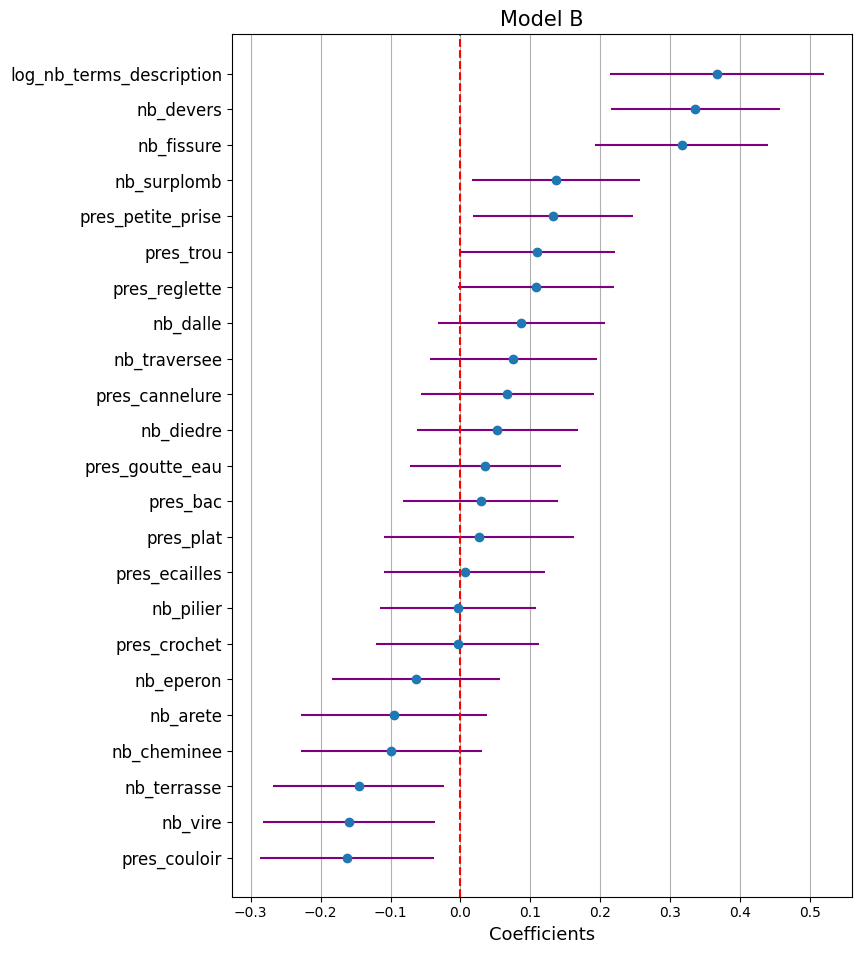

In [10]:
# ============================================================
# 3. RESULTS
# ============================================================
coefs = pd.read_csv(PREFIXE + "_coefficients.csv")
ajust = pd.read_csv(PREFIXE + "_ajustement.csv")
print(ajust.to_string(index=False))
print(coefs.round(3).to_string(index=False))

# Forest plot (coefficients; positive values indicate a higher grade)
coefs = coefs.sort_values("coef").reset_index(drop=True)
y_pos = range(1, len(coefs) + 1)
ci = (coefs["ic_haut"] - coefs["ic_bas"]) / 2

plt.figure(figsize=(8, 0.4 * len(coefs) + 2))
plt.errorbar(coefs["coef"], y_pos, xerr=ci, fmt="o", ecolor="purple")
plt.yticks(y_pos, coefs["variable"], fontsize=12)
plt.axvline(x=0, linestyle="--", color="red")
plt.xlabel("Coefficients", fontsize=13)
plt.title("Model B", fontsize=15)
plt.grid(axis="x")